# Exp no5.
Develop a machine learning model using Support Vector Machine (SVM) to classify real vs. fake images 
using a small dataset of real and AI-generated faces. 

In [15]:
import os
import cv2
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

In [16]:
path = r"C:\Users\kolis\Downloads\05_real_and_fake_face-20261019T050939Z-1-001\05_real_and_fake_face"
print(os.listdir(path))

['training_fake', 'training_real']


In [17]:
# Load the images
X, y, names = [], [], []

# Load 4 real and 4 fake images
for folder, label in [("training_real", 0), ("training_fake", 1)]:
    for file in os.listdir(os.path.join(path, folder))[:4]:
        img = cv2.imread(os.path.join(path, folder, file))
        if img is not None:
            img = cv2.resize(img, (64, 64))
            X.append(img.flatten())
            y.append(label)
            names.append(file)
print("Images loaded:", len(X))

Images loaded: 8


In [18]:
# Check the loaded labels
print("Real images:", y.count(0))
print("Fake images:", y.count(1))

Real images: 4
Fake images: 4


In [19]:
# Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

In [20]:
# Train the SVM model
model = SVC(kernel="linear")
model.fit(X_train, y_train)

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [21]:
# Calculate accuracy
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred) * 100, "%")

Accuracy: 50.0 %


In [22]:
# Predict all loaded images
pred_all = model.predict(X)

for i in range(len(X)):
    if pred_all[i] == 1:
        print(names[i], ": Fake")
    else:
        print(names[i], ": Real")

real_00001.jpg : Real
real_00002.jpg : Real
real_00003.jpg : Fake
real_00004.jpg : Real
easy_100_1111.jpg : Fake
easy_101_0010.jpg : Fake
easy_102_0101.jpg : Fake
easy_103_1111.jpg : Fake


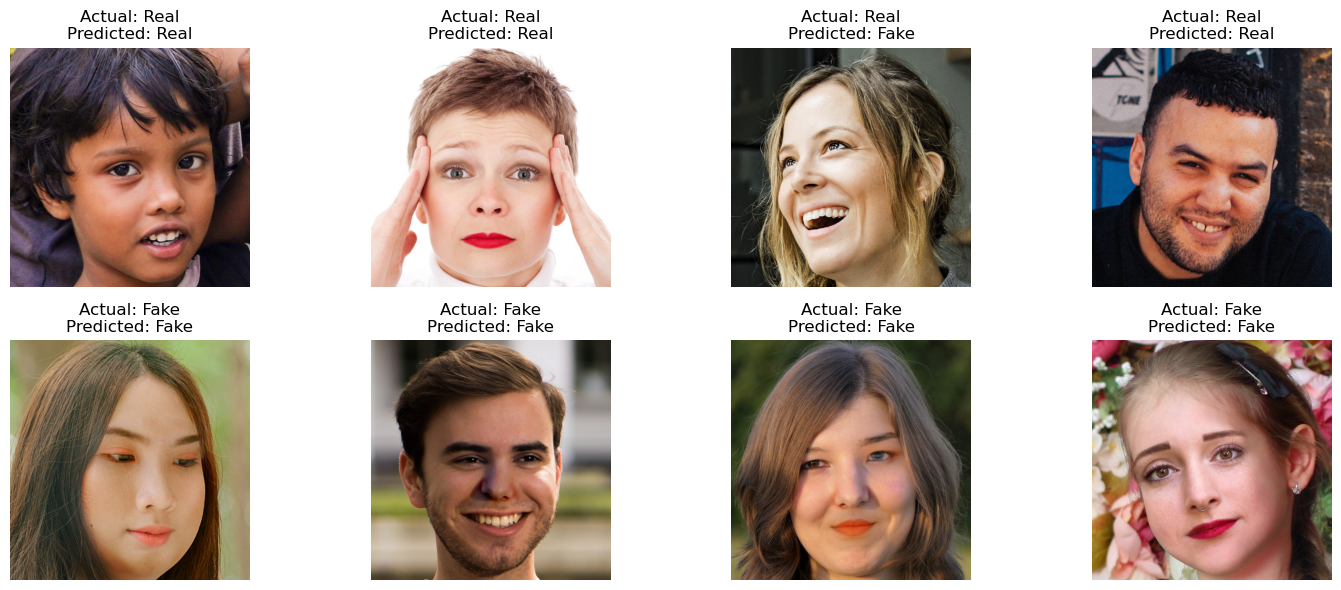

In [23]:
# Visualize actual and predicted labels
real_folder = "training_real"
fake_folder = "training_fake"
plt.figure(figsize=(15, 6))

for i in range(len(X)):
    folder = real_folder if y[i] == 0 else fake_folder
    img = cv2.imread(os.path.join(path, folder, names[i]))
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 4, i + 1)
    plt.imshow(img)

    actual = "Real" if y[i] == 0 else "Fake"
    predicted = "Real" if pred_all[i] == 0 else "Fake"

    plt.title("Actual: " + actual + "\nPredicted: " + predicted)
    plt.axis("off")

plt.tight_layout()
plt.show()